In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python

# Import standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools  
import seaborn as sns
from scipy.stats import zscore

# Import scikit-learn libraries for preprocessing, modeling, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model    import LogisticRegression
from sklearn.tree            import DecisionTreeClassifier
from sklearn.naive_bayes     import GaussianNB
from sklearn.ensemble        import RandomForestClassifier
from sklearn.svm             import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score,
    roc_curve,
    recall_score,
    precision_score,
    f1_score,
)

#import under_sampling
from imblearn.under_sampling import RandomUnderSampler
# Import SMOTE
from imblearn.over_sampling import SMOTE

# Load the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# Inspect first few rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# 1. Drop the customer identifier column
if 'customerID' in df.columns:
    df = df.drop('customerID', axis=1)

# 2. Convert TotalCharges to numeric and impute missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 3. Map binary columns ('Yes'/'No') to 1/0
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].astype(str).str.strip().map({'Yes': 1, 'No': 0})

# 4. Ensure SeniorCitizen is numeric
df['SeniorCitizen'] = pd.to_numeric(df['SeniorCitizen'], errors='coerce').astype(int)

# 5. One-hot encode any remaining object-dtype columns
obj_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=obj_cols, drop_first=True)

# 6. Standardize numerical features
scaler = StandardScaler()
df[['tenure','MonthlyCharges','TotalCharges']] = scaler.fit_transform(
    df[['tenure','MonthlyCharges','TotalCharges']]
)

# Preview processed DataFrame
print(df.head())
print(df.dtypes)


   SeniorCitizen  Partner  Dependents    tenure  PhoneService  \
0              0        1           0 -1.277445             0   
1              0        0           0  0.066327             1   
2              0        0           0 -1.236724             1   
3              0        0           0  0.514251             0   
4              0        0           0 -1.236724             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  gender_Male  ...  \
0                 1       -1.160323     -0.994242      0        False  ...   
1                 0       -0.259629     -0.173244      0         True  ...   
2                 1       -0.362660     -0.959674      1         True  ...   
3                 0       -0.746535     -0.194766      0         True  ...   
4                 1        0.197365     -0.940470      1        False  ...   

   TechSupport_Yes  StreamingTV_No internet service  StreamingTV_Yes  \
0            False                            False            False

Number of outliers (|Z-score| > 3): 0


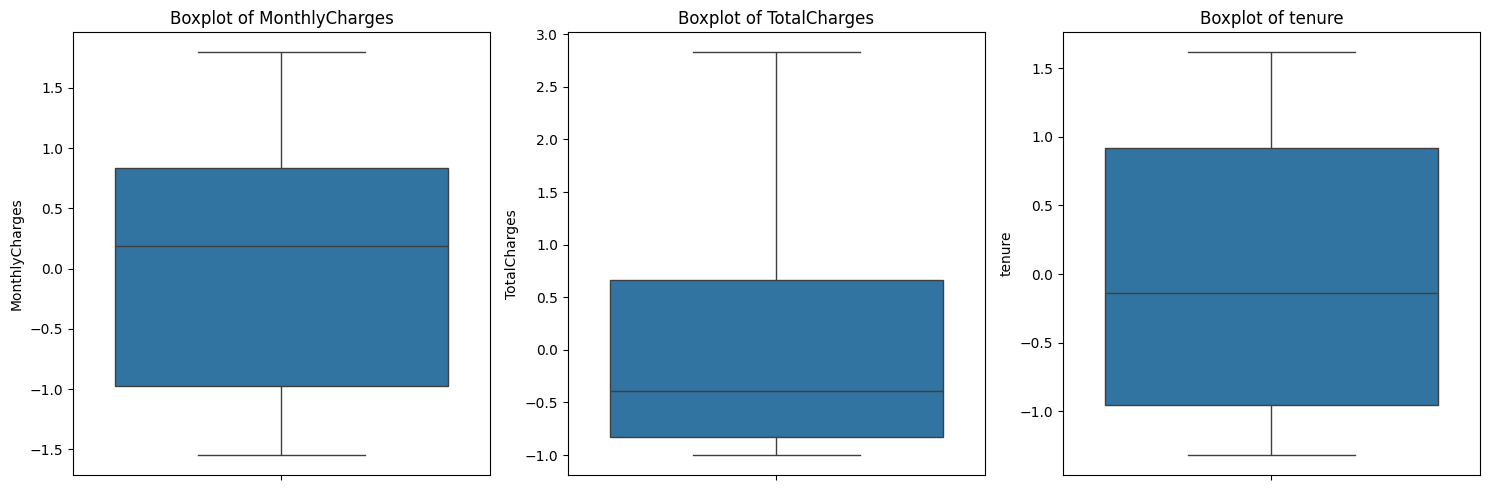

In [7]:
# Outlier detection using Z-score
num_cols = ['MonthlyCharges', 'TotalCharges', 'tenure']
# Calculate Z-scores
z_scores = np.abs(zscore(df[num_cols]))
# Identify outliers (Z-score > 3)
outliers = df[(z_scores > 3).any(axis=1)]
# Display summary of outliers
print(f"Number of outliers (|Z-score| > 3): {len(outliers)}")

# Boxplots for numerical features
plt.figure(figsize=(15, 5))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)  
    sns.boxplot(data=df, y=col)
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(22, 18))

#Compute correlation matrix, excluding 'Churn'
corr_matrix = df.drop('Churn', axis=1).corr(numeric_only=True)

sns.heatmap(
    corr_matrix, 
    cmap='coolwarm', 
    annot=True, 
    fmt=".2f", 
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": 0.75},
    annot_kws={"size": 8}
)

plt.xticks(rotation=45, ha='right', fontsize=12, fontweight='bold')
plt.yticks(rotation=0, fontsize=12, fontweight='bold')
plt.title("Correlation Heatmap of Telco Customer Churn Data", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

In [3]:
# Prepare data
from typing import Counter
from sklearn.feature_selection import RFECV, SelectKBest, f_classif
from sklearn.metrics import make_scorer

X = df.drop('Churn', axis=1)
y = df['Churn']

# Run SelectKBest
selectk = SelectKBest(f_classif, k=5)
selectk.fit(X, y)
selectk_features = X.columns[selectk.get_support()]

# Define models with their names
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}

print("\n=== Model-Based Feature Selection (RFECV) Results ===")

scorer = make_scorer(recall_score)

# Dictionary to store results and rankings for each model
model_results = {}
all_eliminated_features = []

# Run RFECV once for each model
for name, model in models.items():
    selector = RFECV(estimator=model, step=1, scoring=scorer, n_jobs=-1)
    selector.fit(X, y)
    
    # Get features and their rankings
    feature_ranks = list(zip(X.columns, selector.ranking_))
    
    # Separate selected and eliminated features
    eliminated_features = [feature for feature, rank in feature_ranks if rank > 1]
    selected_features = [feature for feature, rank in feature_ranks if rank == 1]
    
    # Store results for this model
    model_results[name] = {
        'Eliminated': eliminated_features,
        'Selected': selected_features
    }
    
    # Add eliminated features to the overall list
    all_eliminated_features.extend(eliminated_features)



# Create DataFrame with features as rows
rows = ['Eliminated Features', 'Selected Features']
results_df = pd.DataFrame(index=rows)

# Fill in the DataFrame
for model_name, result in model_results.items():
    results_df[model_name] = [
        ', '.join(result['Eliminated']),
        ', '.join(result['Selected'])
    ]

# Set display options to show full content
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
display(results_df)

# Display Top 5 selected features
print("\nTop 5 selected features:", selectk_features.tolist())

# Find commonly eliminated features
feature_counts = Counter(all_eliminated_features)
# Sort by frequency (most common first) and then by feature name
most_common_eliminated = sorted(
    [(feature, count) for feature, count in feature_counts.items()],
    key=lambda x: (-x[1], x[0])
)

# Format eliminated features list
eliminated_features_list = [f"{feature}" for feature, count in most_common_eliminated[:5]]
print("\nTop 5 most commonly eliminated features:", eliminated_features_list)

print("\nNote: GaussianNB and SVC are excluded as they don't support feature importance.")


=== Model-Based Feature Selection (RFECV) Results ===


,Logistic Regression,Decision Tree,Random Forest
Eliminated Features,"SeniorCitizen, Partner, Dependents, tenure, PhoneService, PaperlessBilling, MonthlyCharges, TotalCharges, gender_Male, MultipleLines_No phone service, MultipleLines_Yes, InternetService_No, OnlineSecurity_No internet service, OnlineSecurity_Yes, OnlineBackup_No internet service, OnlineBackup_Yes, DeviceProtection_No internet service, DeviceProtection_Yes, TechSupport_No internet service, TechSupport_Yes, StreamingTV_No internet service, StreamingTV_Yes, StreamingMovies_No internet service, StreamingMovies_Yes, PaymentMethod_Credit card (automatic), PaymentMethod_Electronic check, PaymentMethod_Mailed check","InternetService_No, OnlineSecurity_No internet service, OnlineBackup_No internet service, DeviceProtection_No internet service, TechSupport_No internet service, StreamingMovies_No internet service","PhoneService, MultipleLines_No phone service, InternetService_No, OnlineSecurity_No internet service, OnlineBackup_No internet service, DeviceProtection_No internet service, TechSupport_No internet service, StreamingTV_No internet service, StreamingTV_Yes, StreamingMovies_No internet service, PaymentMethod_Credit card (automatic), PaymentMethod_Mailed check"
Selected Features,"InternetService_Fiber optic, Contract_One year, Contract_Two year","SeniorCitizen, Partner, Dependents, tenure, PhoneService, PaperlessBilling, MonthlyCharges, TotalCharges, gender_Male, MultipleLines_No phone service, MultipleLines_Yes, InternetService_Fiber optic, OnlineSecurity_Yes, OnlineBackup_Yes, DeviceProtection_Yes, TechSupport_Yes, StreamingTV_No internet service, StreamingTV_Yes, StreamingMovies_Yes, Contract_One year, Contract_Two year, PaymentMethod_Credit card (automatic), PaymentMethod_Electronic check, PaymentMethod_Mailed check","SeniorCitizen, Partner, Dependents, tenure, PaperlessBilling, MonthlyCharges, TotalCharges, gender_Male, MultipleLines_Yes, InternetService_Fiber optic, OnlineSecurity_Yes, OnlineBackup_Yes, DeviceProtection_Yes, TechSupport_Yes, StreamingMovies_Yes, Contract_One year, Contract_Two year, PaymentMethod_Electronic check"



Top 5 selected features: ['tenure', 'InternetService_Fiber optic', 'StreamingMovies_No internet service', 'Contract_Two year', 'PaymentMethod_Electronic check']

Top 5 most commonly eliminated features: ['DeviceProtection_No internet service', 'InternetService_No', 'OnlineBackup_No internet service', 'OnlineSecurity_No internet service', 'StreamingMovies_No internet service']

Note: GaussianNB and SVC are excluded as they don't support feature importance.


Original Training features shape: (5634, 30)
Original Testing features shape:  (1409, 30)

Class distribution after SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


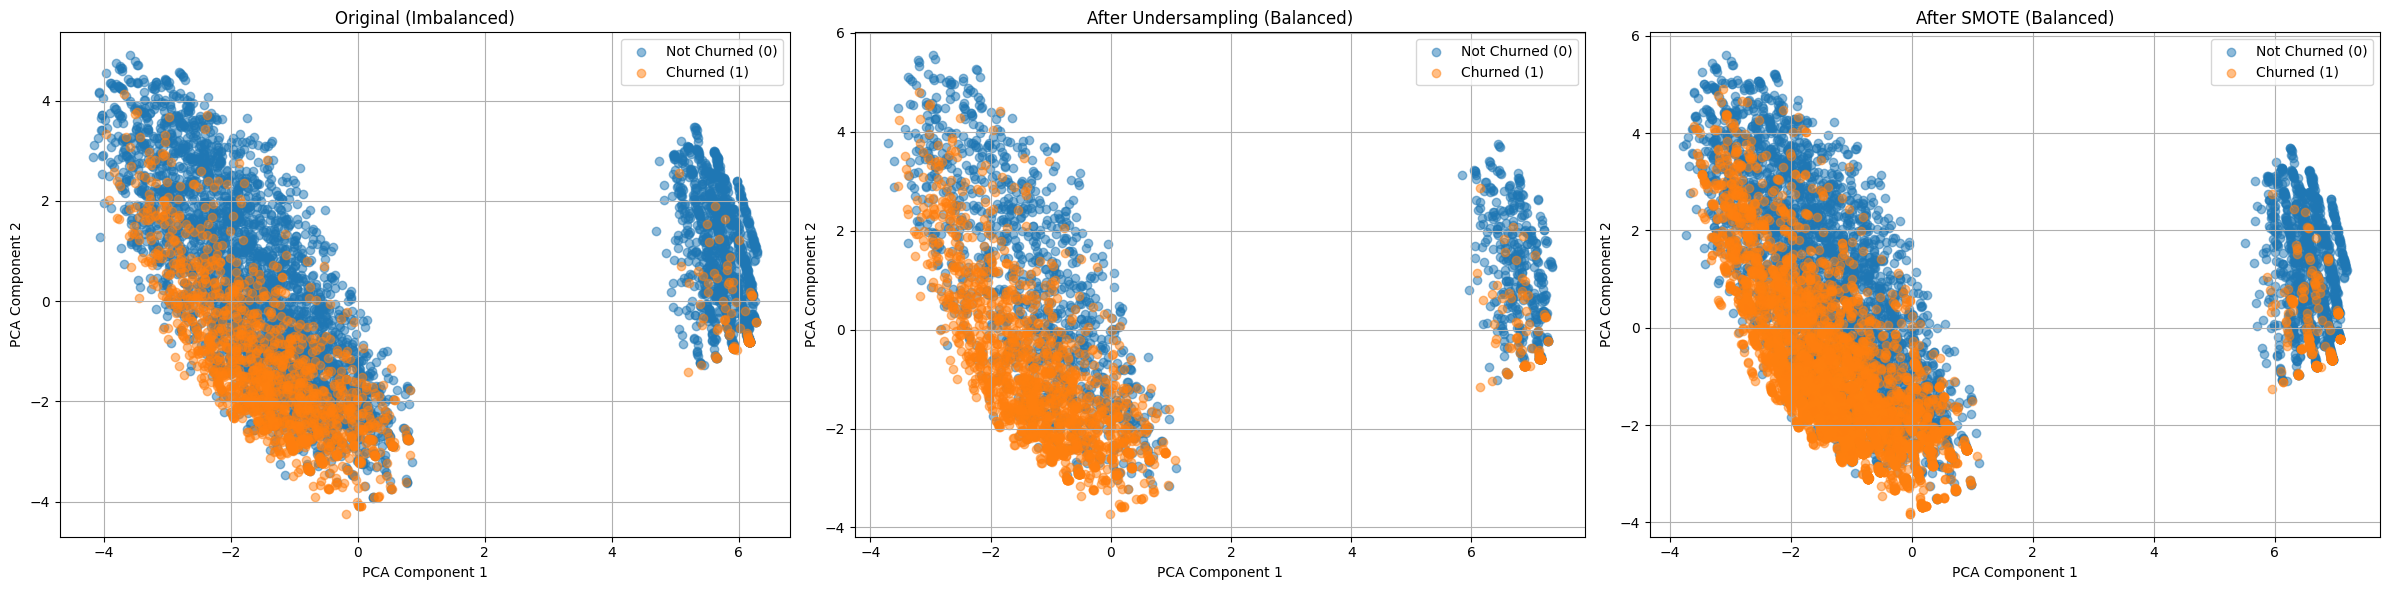

In [4]:
# Define features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

# Split into train/test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Original Training features shape: {X_train.shape}")
print(f"Original Testing features shape:  {X_test.shape}")

# Resample Datasets
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

smote = SMOTE(random_state=42, k_neighbors=2)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Organize datasets
datasets = {
    'Original': (X_train, y_train, X_test, y_test),
    'Undersampling': (X_train_under, y_train_under, X_test, y_test),
    'SMOTE': (X_train_smote, y_train_smote, X_test, y_test)
}

# Check SMOTE class distribution
print("\nClass distribution after SMOTE:")
print(pd.Series(datasets['SMOTE'][1]).value_counts())

# Scale and apply PCA (reduce to 2D) for each dataset
pca_results = {}
for setting, (X_tr, y_tr, _, _) in datasets.items():
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_tr)
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    pca_results[setting] = (X_pca, y_tr)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(24, 6))

titles = ['Original (Imbalanced)', 'After Undersampling (Balanced)', 'After SMOTE (Balanced)']

for ax, (method, (X_pca, y_resampled)), title in zip(axes, pca_results.items(), titles):
    ax.scatter(X_pca[y_resampled == 0, 0], X_pca[y_resampled == 0, 1], alpha=0.5, label='Not Churned (0)')
    ax.scatter(X_pca[y_resampled == 1, 0], X_pca[y_resampled == 1, 1], alpha=0.5, label='Churned (1)')
    ax.set_title(title)
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [5]:
# Initialize and train models
lr_model  = LogisticRegression(random_state=42, max_iter=1000)
dt_model  = DecisionTreeClassifier(random_state=42)
nb_model  = GaussianNB()
rf_model  = RandomForestClassifier(random_state=42, n_estimators=100)
svm_model = SVC(probability=True, random_state=42)

models = [lr_model, dt_model, nb_model, rf_model, svm_model]
model_names = ['Logistic Regression', 'Decision Tree', 'Naive Bayes', 'Random Forest', 'SVM']

# Create an empty list to store performance metrics
performance_summary = []

# Now loop through datasets
for setting, (X_tr, y_tr, X_te, y_te) in datasets.items():
    print(f"\n\n{'='*30}\nRunning models on: {setting}\n{'='*30}")

    # Re-initialize new models for each dataset to avoid memory carryover
    models = [
        LogisticRegression(random_state=42, max_iter=1000),
        DecisionTreeClassifier(random_state=42),
        GaussianNB(),
        RandomForestClassifier(random_state=42, n_estimators=100),
        SVC(probability=True, random_state=42)
    ]

    # Now train and evaluate each model
    for model, model_name in zip(models, model_names):
        model.fit(X_tr, y_tr)
        
        # Predict
        y_pred = model.predict(X_te)
        
        # Predict probabilities for ROC-AUC
        if hasattr(model, "predict_proba"):
            y_pred_proba = model.predict_proba(X_te)[:, 1]
        else:
            y_pred_proba = model.decision_function(X_te)

        # Print classification report (like you do now)
        from sklearn.metrics import classification_report
        print(f"\nModel: {model_name}")
        print(classification_report(y_te, y_pred))
        
        # Save performance metrics
        performance_summary.append({
            'Setting': setting,
            'Model': model_name,
            'Accuracy': accuracy_score(y_te, y_pred),
            'Recall': recall_score(y_te, y_pred),
            'Precision': precision_score(y_te, y_pred),
            'F1-Score': f1_score(y_te, y_pred),
            'ROC-AUC': roc_auc_score(y_te, y_pred_proba)
        })

print ('\nAll models have been initialized, trained, and evaluated across all datasets.')



Running models on: Original

Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


Model: Decision Tree
              precision    recall  f1-score   support

           0       0.82      0.82      0.82      1035
           1       0.51      0.52      0.51       374

    accuracy                           0.74      1409
   macro avg       0.66      0.67      0.67      1409
weighted avg       0.74      0.74      0.74      1409


Model: Naive Bayes
              precision    recall  f1-score   support

           0       0.92      0.58      0.71      1035
           1       0.43      0.87      0.57       374

    accuracy                           0.66      1409
   macro avg       0.67     

,Setting,Model,Accuracy,Recall,Precision,F1-Score,ROC-AUC
0,Original,Logistic Regression,0.804826,0.558824,0.655172,0.603175,0.841995
1,Original,Decision Tree,0.737402,0.518717,0.505208,0.511873,0.667106
2,Original,Naive Bayes,0.655784,0.866310,0.426877,0.571933,0.809254
3,Original,Random Forest,0.792051,0.505348,0.636364,0.563338,0.822979
4,Original,SVM,0.794890,0.481283,0.654545,0.554700,0.794940
5,Undersampling,Logistic Regression,0.743080,0.783422,0.510453,0.618143,0.842923
6,Undersampling,Decision Tree,0.692690,0.676471,0.447788,0.538871,0.687198
7,Undersampling,Naive Bayes,0.649397,0.879679,0.422879,0.571181,0.808246
8,Undersampling,Random Forest,0.745209,0.767380,0.513417,0.615220,0.826256
9,Undersampling,SVM,0.745209,0.802139,0.512821,0.625652,0.830157


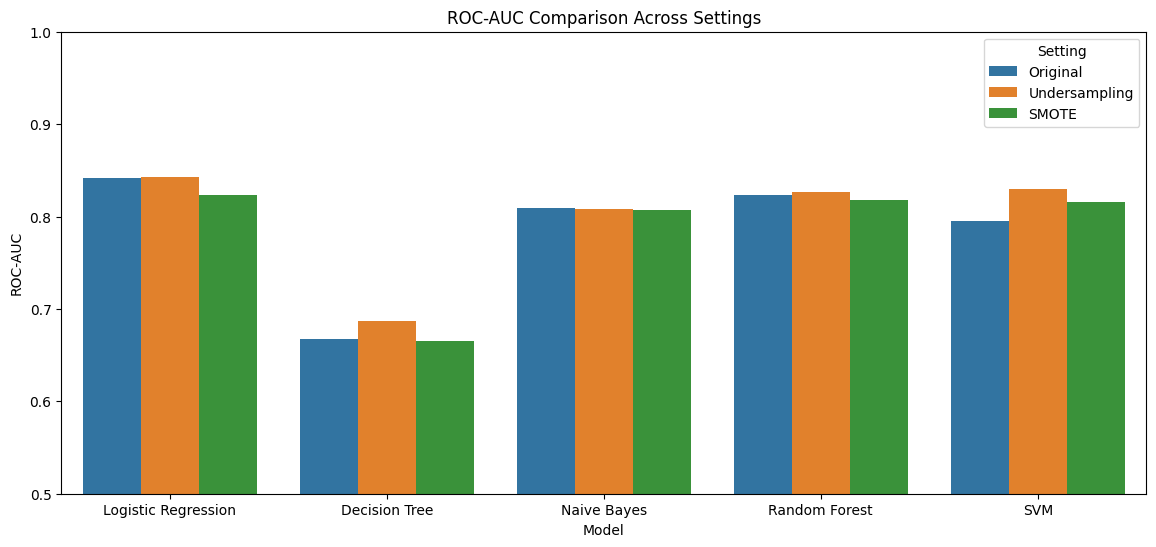

In [6]:
# Create performance DataFrame
performance_df = pd.DataFrame(performance_summary)

# Display results
display(performance_df)

# Optional: plot ROC-AUC comparisons
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
sns.barplot(data=performance_df, x='Model', y='ROC-AUC', hue='Setting')
plt.title('ROC-AUC Comparison Across Settings')
plt.ylim(0.5, 1)
plt.show()

In [7]:
# Get models and predictions from undersampled dataset
# Use the models trained on undersampled data
undersampled_data = datasets['Undersampling']
X_train_under, y_train_under, X_test, y_test = undersampled_data

# Make predictions and get probabilities using undersampled models
y_pred_lr = models[0].predict(X_test)
y_pred_dt = models[1].predict(X_test)
y_pred_nb = models[2].predict(X_test)
y_pred_rf = models[3].predict(X_test)
y_pred_svm = models[4].predict(X_test)

y_prob_lr = models[0].predict_proba(X_test)[:, 1]
y_prob_dt = models[1].predict_proba(X_test)[:, 1]
y_prob_nb = models[2].predict_proba(X_test)[:, 1]
y_prob_rf = models[3].predict_proba(X_test)[:, 1]
y_prob_svm = models[4].predict_proba(X_test)[:, 1]



In [8]:
# Compute accuracy and AUC scores for undersampled models
accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_nb = accuracy_score(y_test, y_pred_nb)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_dt = roc_auc_score(y_test, y_prob_dt)
auc_nb = roc_auc_score(y_test, y_prob_nb)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_svm = roc_auc_score(y_test, y_prob_svm)

print("Results from Undersampled Models:")
print("Logistic Regression: Accuracy = {:.4f}, AUC = {:.4f}".format(accuracy_lr, auc_lr))
print("Decision Tree:       Accuracy = {:.4f}, AUC = {:.4f}".format(accuracy_dt, auc_dt))
print("Naive Bayes:         Accuracy = {:.4f}, AUC = {:.4f}".format(accuracy_nb, auc_nb))
print("Random Forest:       Accuracy = {:.4f}, AUC = {:.4f}".format(accuracy_rf, auc_rf))
print("SVM:                 Accuracy = {:.4f}, AUC = {:.4f}".format(accuracy_svm, auc_svm))

Results from Undersampled Models:
Logistic Regression: Accuracy = 0.7296, AUC = 0.8233
Decision Tree:       Accuracy = 0.7111, AUC = 0.6649
Naive Bayes:         Accuracy = 0.6437, AUC = 0.8068
Random Forest:       Accuracy = 0.7679, AUC = 0.8181
SVM:                 Accuracy = 0.7502, AUC = 0.8157


## 7. Why these metrics?
- **ROC-AUC** measures how well the model ranks positive vs. negative examples, independent of any threshold.  
- **Confusion matrix & classification report** show actual counts (and precision/recall/F1) at our chosen 0.5 cutoff.


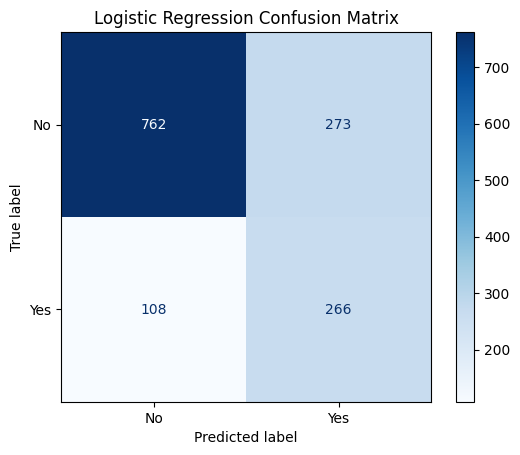

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1035
           1       0.49      0.71      0.58       374

    accuracy                           0.73      1409
   macro avg       0.68      0.72      0.69      1409
weighted avg       0.77      0.73      0.74      1409



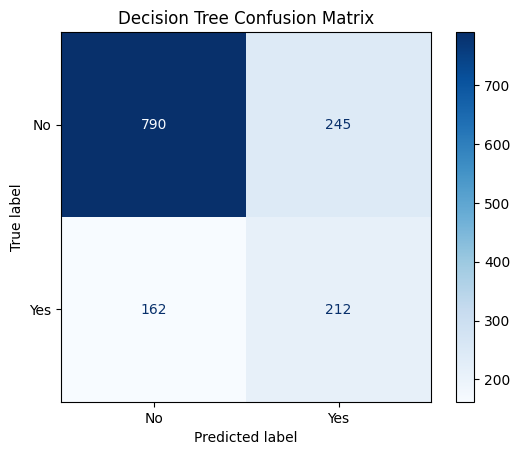

=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

           0       0.83      0.76      0.80      1035
           1       0.46      0.57      0.51       374

    accuracy                           0.71      1409
   macro avg       0.65      0.67      0.65      1409
weighted avg       0.73      0.71      0.72      1409



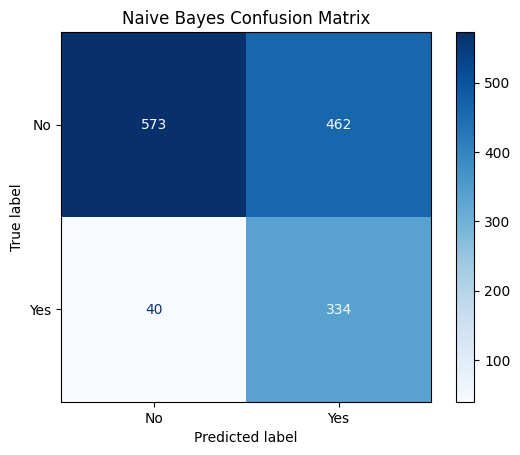

=== Naive Bayes Classification Report ===
              precision    recall  f1-score   support

           0       0.93      0.55      0.70      1035
           1       0.42      0.89      0.57       374

    accuracy                           0.64      1409
   macro avg       0.68      0.72      0.63      1409
weighted avg       0.80      0.64      0.66      1409



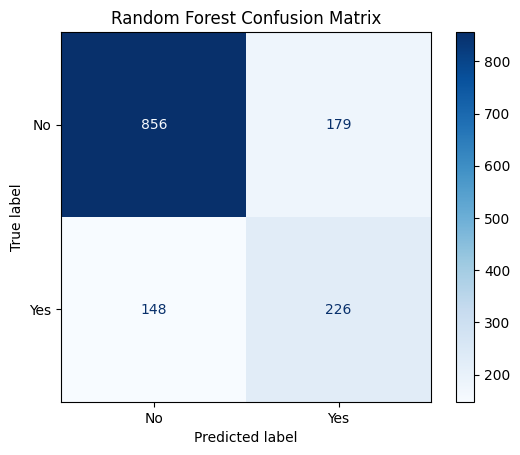

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      1035
           1       0.56      0.60      0.58       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.77      0.77      0.77      1409



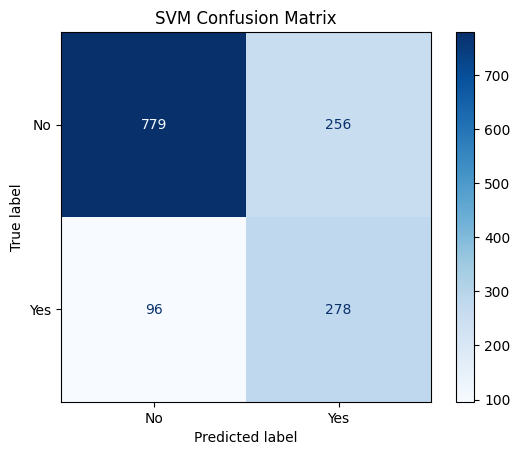

=== SVM Classification Report ===
              precision    recall  f1-score   support

           0       0.89      0.75      0.82      1035
           1       0.52      0.74      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

model_dict = {
    'Logistic Regression': models[0],
    'Decision Tree': models[1],
    'Naive Bayes': models[2],
    'Random Forest': models[3],
    'SVM': models[4]
}

for name, model in model_dict.items():
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=['No','Yes'],
        cmap=plt.cm.Blues
    )
    disp.ax_.set_title(f"{name} Confusion Matrix")
    plt.show()
    
    # Print the classification report
    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, model.predict(X_test)))


In [10]:
# Example predictions output
print("\nLogistic Regression predictions (first 5):")
for i, prob in enumerate(y_prob_lr[:5]):
    print(f"Customer {i}: {prob*100:.2f}% chance to churn")

print("\nDecision Tree hard predictions (first 5):")
for i, prob in enumerate(y_prob_dt[:5]):
    print(f"Customer {i}: {'Yes' if prob>=0.5 else 'No'}")

print("\nNaive Bayes hard predictions (first 5):")
for i, prob in enumerate(y_prob_nb[:5]):
    print(f"Customer {i}: {'Yes' if prob>=0.5 else 'No'}")



Logistic Regression predictions (first 5):
Customer 0: 13.43% chance to churn
Customer 1: 78.79% chance to churn
Customer 2: 5.16% chance to churn
Customer 3: 77.22% chance to churn
Customer 4: 7.80% chance to churn

Decision Tree hard predictions (first 5):
Customer 0: No
Customer 1: Yes
Customer 2: No
Customer 3: Yes
Customer 4: No

Naive Bayes hard predictions (first 5):
Customer 0: No
Customer 1: Yes
Customer 2: No
Customer 3: Yes
Customer 4: No


## 9. ROC Curves
We use each model’s `predict_proba(X_test)[:,1]` output to build ROC curves.  
The area under each curve (AUC) summarizes its overall ranking performance.


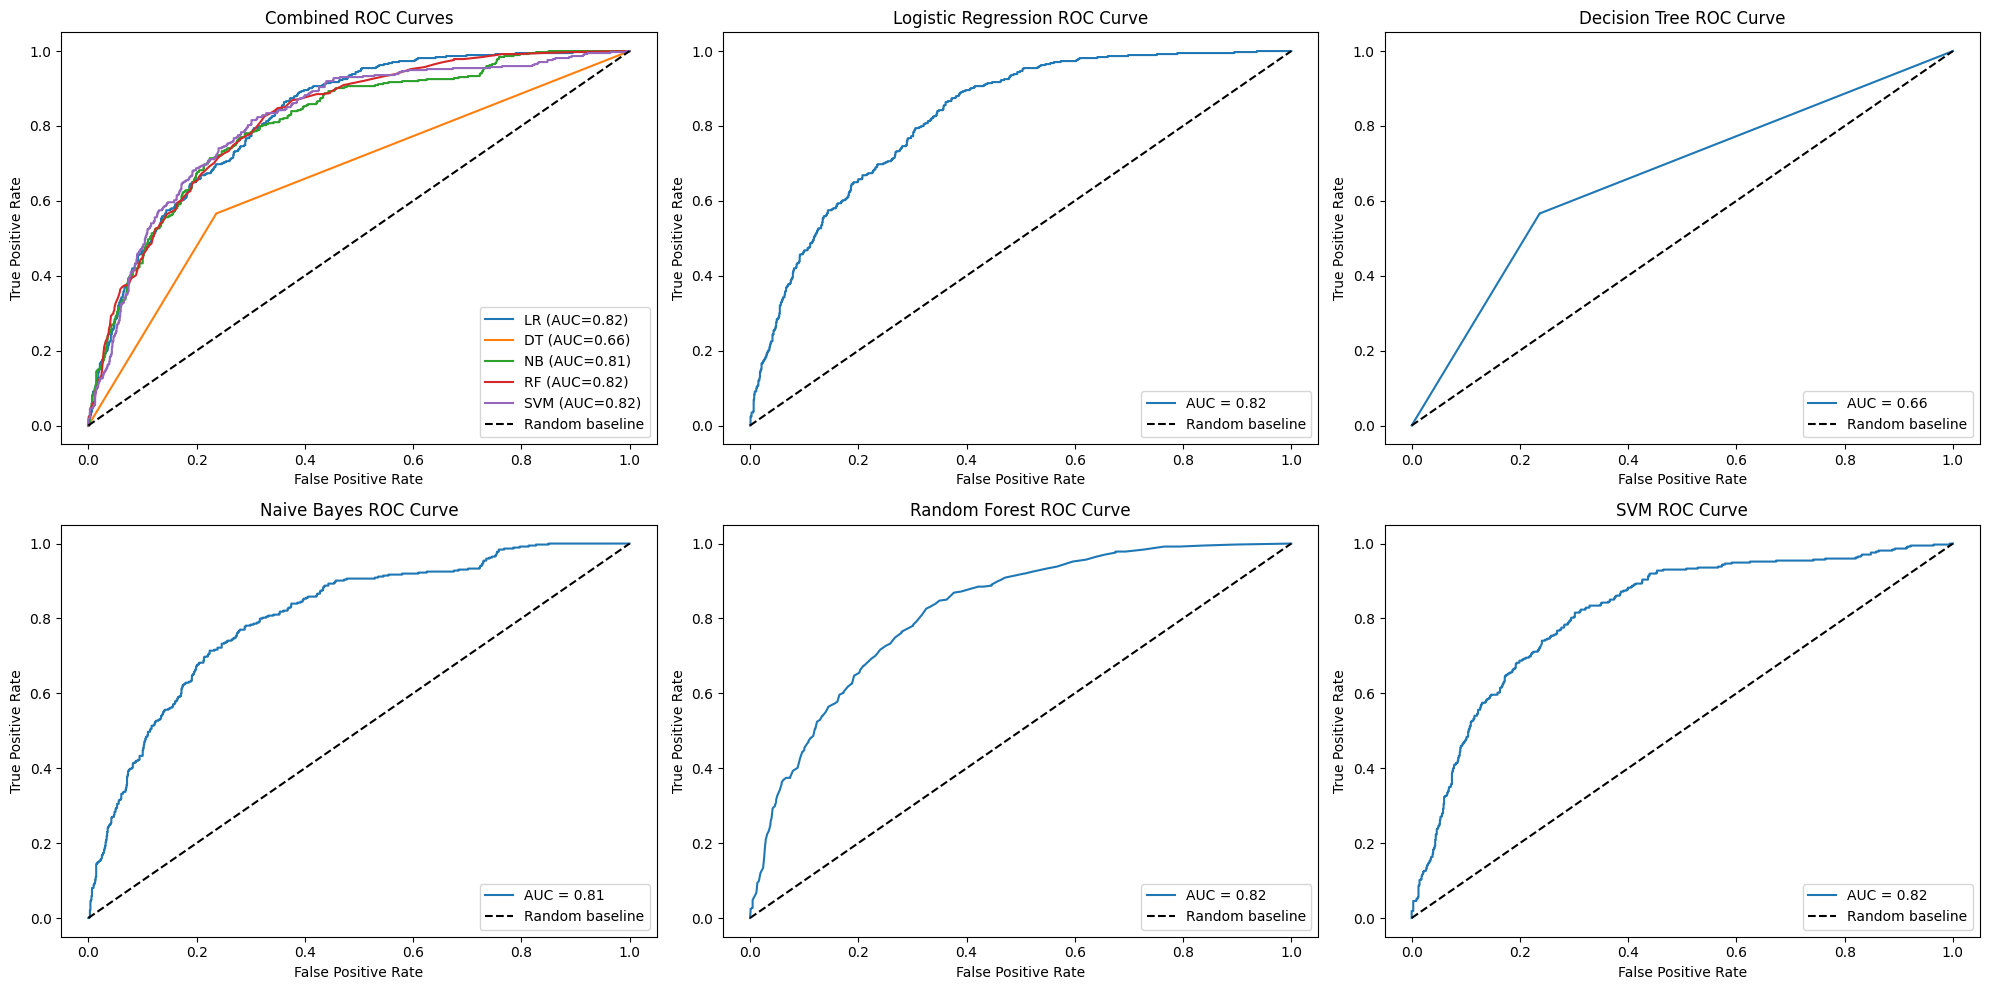

In [11]:
# Plot ROC curves - combined and individual
fig = plt.figure(figsize=(20, 10))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

# Combined ROC curve - left plot
plt.subplot(2, 3, 1)
roc_data = {
    'LR': (fpr_lr, tpr_lr, auc_lr),
    'DT': (fpr_dt, tpr_dt, auc_dt),
    'NB': (fpr_nb, tpr_nb, auc_nb),
    'RF': (fpr_rf, tpr_rf, auc_rf),
    'SVM': (fpr_svm, tpr_svm, auc_svm)
}

for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")

plt.plot([0,1], [0,1], 'k--', label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Combined ROC Curves")
plt.legend(loc="lower right")

# Individual ROC curves - right plots
model_names = ['Logistic Regression', 'Decision Tree', 'Naive Bayes', 'Random Forest', 'SVM']
roc_curves = [
    (fpr_lr, tpr_lr, auc_lr),
    (fpr_dt, tpr_dt, auc_dt),
    (fpr_nb, tpr_nb, auc_nb),
    (fpr_rf, tpr_rf, auc_rf),
    (fpr_svm, tpr_svm, auc_svm)
]

for idx, (name, (fpr, tpr, auc)) in enumerate(zip(model_names, roc_curves), 2):
    plt.subplot(2, 3, idx)
    plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
    plt.plot([0,1], [0,1], 'k--', label="Random baseline")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend(loc="lower right")

plt.tight_layout()
plt.show()